Exo 7 TP2

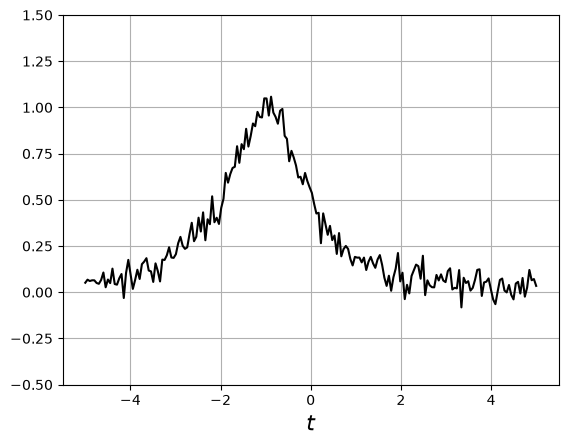

In [1]:
import numpy as np
import msicpe.mana as mana
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt


# fonction lorentzienne
def f(t):
    return (1+(1+t)**2)**(-1)

# signal bruité
tmin=-5.0
tmax=5.0
N=200
Te=(tmax-tmin)/N
t=np.linspace(tmin,tmax,N)
noise=np.random.normal(0,0.05,N) # bruit gaussien
y=f(t)+noise
plt.figure(1)
plt.plot(t,y,'k-')
plt.grid()
plt.xlabel(f'$t$',fontsize=16)
plt.ylim([-0.5,1.5])

#signal clean
t = np.linspace(-5, 5, 200)
dt = t[1] - t[0]

Delta = 1
def porte(Delta):
    return  (1/Delta)*mana.porte(t/Delta)

g05 = np.convolve(porte(0.5), y, 'same')*dt
g1 = np.convolve(porte(1), y, 'same')*dt
g2 = np.convolve(porte(2), y, 'same')*dt
g4 = np.convolve(porte(4), y, 'same')*dt
g8 = np.convolve(porte(8), y, 'same')*dt
g20 = np.convolve(porte(20), y, 'same')*dt
g50 = np.convolve(porte(50), y, 'same')*dt

df = pd.DataFrame({"g05":g05, "g1":g1,"g2":g2,"g4":g4,"g8":g8,"g20":g20,"g50":g50,})
fig = px.line(df, t, ["g05", "g1", "g2", "g4", "g8", "g20", "g50"], title='signal convolué avec une porte')
fig.show()

Plus le delta augmente, plus la fonction est lisse, cependant, pour un delta trop élevé, la fonction semble tendre vers 0

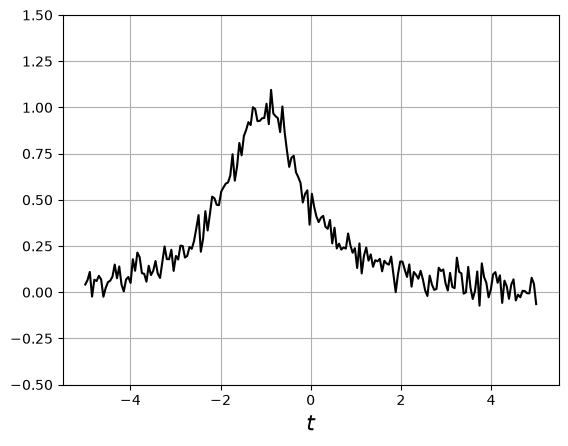

In [ ]:

# signal bruité
tmin=-5.0
tmax=5.0
N=200
Te=(tmax-tmin)/N
t=np.linspace(tmin,tmax,N)
noise=np.random.normal(0,0.05,N) # bruit gaussien
y=f(t)+noise
plt.figure(1)
plt.plot(t,y,'k-')
plt.grid()
plt.xlabel(f'$t$',fontsize=16)
plt.ylim([-0.5,1.5])


Y, nu = mana.trans_fourier(y, t)

Re = np.real(Y)
Im = np.imag(Y)

df = pd.DataFrame({"t":t, "Re":Re, "Im":Im})

fig = px.line(df, t, ['Re', 'Im'], title = 'Re et Im du signal transformé de fourier')
fig.show()

In [ ]:
t = np.linspace(-2, 2, 200)

# signal bruité
tmin=-5.0
tmax=5.0
N=200
Te=(tmax-tmin)/N
t=np.linspace(tmin,tmax,N)
noise=np.random.normal(0,0.05,N) # bruit gaussien
y=f(t)+noise
plt.figure(1)
plt.plot(t,y,'k-')
plt.grid()
plt.xlabel(f'$t$',fontsize=16)
plt.ylim([-0.5,1.5])


Y, nu = mana.trans_fourier(y, t)

porte = mana.porte(t)

G = mana.trans_fourier_inv(Y, porte)